# Chest X-ray Classification

Three-class lung X-ray classification (Normal, Opacity, Pneumonia) comparing a custom CNN, ResNet-18 and RegNet-Y-400MF under several transfer-learning strategies.
Team project, MSc Data Science and AI, University of Liverpool.

## Setup

This notebook is configured for local desktop use. Dataset loading is handled in the next dedicated cell and expects the folder structure `dataset/Normal`, `dataset/Opacity`, and `dataset/Pneumonia`.

In [1]:
# Core imports, reproducibility, and device setup.
from pathlib import Path
import json
import os
import random
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from IPython.display import Markdown, display
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    matthews_corrcoef,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision.models import (
    RegNet_Y_400MF_Weights,
    ResNet18_Weights,
    regnet_y_400mf,
    resnet18,
)

# Keep Matplotlib's cache inside a writable folder without changing PyTorch's model cache.
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

# Consistent notebook display styling.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})



def display_table(title, dataframe, note=None):
    """Display a DataFrame with a clear report-style heading and optional note."""
    display(Markdown(f"### {title}"))
    if note is not None:
        display(Markdown(note))
    display(dataframe)


MODEL_LABELS = {
    "Custom CNN Scratch lr=1e-3": "Custom CNN Scratch",
    "Custom CNN Scratch lr=3e-4": "Custom CNN Scratch + Dropout",
    "ResNet18 Scratch lr=1e-3": "ResNet-18 Scratch",
    "ResNet18 Feature Extractor lr=1e-3": "ResNet-18 Feature Extractor",
    "ResNet18 Fine-Tuning lr=1e-4": "ResNet-18 Fine-Tune",
    "ResNet18 Fine-Tuning lr=3e-5": "ResNet-18 Fine-Tune (Lower LR)",
    "ResNet18 Fine-Tuning Dropout lr=1e-4": "ResNet-18 Fine-Tune + Dropout",
    "RegNet-Y-400MF Fine-Tuning lr=1e-4": "RegNet-Y-400MF Fine-Tune",
}


def format_model_name(model_name):
    """Return a concise, report-friendly label for a model experiment."""
    return MODEL_LABELS.get(model_name, model_name)


def format_learning_rate(value):
    """Format learning rates without rounding small values to zero."""
    return f"{value:.0e}"


def format_parameter_count(value):
    """Format parameter counts compactly for result tables."""
    if value < 1_000_000:
        return f"{value / 1_000:.1f}K"
    return f"{value / 1_000_000:.2f}M"

SEED = 42

def set_seed(seed=SEED):
    """Fix random seeds so repeated notebook runs use the same split and initialisation."""
    # Python, NumPy, and PyTorch each maintain their own random number generators.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        # CUDA-specific settings reduce run-to-run variation on GPU machines.
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    # Apple Silicon acceleration, if available.
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")
print(f"Random seed fixed at: {SEED}")

Using device: mps
Random seed fixed at: 42


In [2]:
# Dedicated local dataset-loading cell.
# Keep dataset discovery isolated here so the rest of the notebook uses DATASET_ROOT and full_dataset.

def resolve_dataset_root():
    """Find the local dataset folder and verify the expected class subfolders exist."""
    # These candidates cover running the notebook from this folder or with a data/ subfolder.
    candidate_roots = [
        Path.cwd() / "dataset",
        Path.cwd() / "data" / "dataset",
    ]

    for candidate in candidate_roots:
        if candidate.exists() and candidate.is_dir():
            # ImageFolder requires one subdirectory per class.
            class_dirs = {p.name for p in candidate.iterdir() if p.is_dir()}
            expected = {"Normal", "Opacity", "Pneumonia"}
            if expected.issubset(class_dirs):
                return candidate.resolve()

    # Fail early with a useful message rather than failing later inside ImageFolder.
    searched = "\n".join(str(path) for path in candidate_roots)
    raise FileNotFoundError(
        "Dataset folder not found. Expected a local folder containing Normal, Opacity, and Pneumonia.\n"
        f"Searched:\n{searched}"
    )

DATASET_ROOT = resolve_dataset_root()
# Load labels once without transforms so the split and class counts are based on raw metadata.
full_dataset = datasets.ImageFolder(root=str(DATASET_ROOT), transform=None)
labels = np.asarray(full_dataset.targets)
class_names = full_dataset.classes
num_classes = len(class_names)

print(f"Dataset root: {DATASET_ROOT}")
print(f"Total images: {len(full_dataset)}")
print(f"Classes: {class_names}")

overall_counts = pd.DataFrame({
    "class": class_names,
    "count": np.bincount(labels, minlength=num_classes),
})
display(overall_counts)

Dataset root: dataset
Total images: 3475
Classes: ['Normal', 'Opacity', 'Pneumonia']


,class,count
0,Normal,1250
1,Opacity,1125
2,Pneumonia,1100


# 1. Data Management

The protocol is a stratified `70/15/15` train, validation, and test split. The validation split is used for model selection and hyperparameter choice; the test split is used once for the final selected model. Training uses augmentation and weighted sampling to reduce the effect of class imbalance.

In [3]:
IMG_SIZE = 299
BATCH_SIZE = 32
NUM_WORKERS = 2
PIN_MEMORY = device.type == "cuda"
PERSISTENT_WORKERS = NUM_WORKERS > 0

# The pretrained CNN weights were learned using ImageNet normalization.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training transforms include mild augmentation to improve generalisation without distorting medical structure.
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=8),
    transforms.RandomAffine(degrees=0, translate=(0.03, 0.03), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Validation/test transforms are deterministic so evaluation is stable and fair.
eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# First split: hold out 30% for validation+test while preserving class proportions.
train_idx, temp_idx = train_test_split(
    np.arange(len(labels)),
    test_size=0.30,
    stratify=labels,
    random_state=SEED,
)
# Second split: divide the 30% holdout equally into validation and test sets.
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=labels[temp_idx],
    random_state=SEED,
)

# Separate ImageFolder instances keep the split transforms clear while building dataloaders only once.
train_base_dataset = datasets.ImageFolder(DATASET_ROOT, transform=train_transforms)
eval_base_dataset = datasets.ImageFolder(DATASET_ROOT, transform=eval_transforms)

# These split datasets are reused by every CNN experiment below.
train_set = Subset(train_base_dataset, train_idx)
val_set = Subset(eval_base_dataset, val_idx)
test_set = Subset(eval_base_dataset, test_idx)

# Correct class-weight sampler. Using a NumPy array avoids list-scalar comparison bugs.
# The sampler makes minority classes appear more often during training batches.
train_labels = labels[train_idx]
train_class_counts = np.bincount(train_labels, minlength=num_classes)
class_weights = 1.0 / train_class_counts
sample_weights = class_weights[train_labels]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights),
    replacement=True,
)

# Shared dataloader options keep all experiments on exactly the same data protocol.
loader_kwargs = {
    "num_workers": NUM_WORKERS,
    "pin_memory": PIN_MEMORY,
}
if PERSISTENT_WORKERS:
    loader_kwargs["persistent_workers"] = True

# Dataloaders provide mini-batches to the training, validation, and test loops.
# They are created once here and reused by all CNNs.
train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    **loader_kwargs,
)
val_loader = DataLoader(
    val_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    **loader_kwargs,
)
test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    **loader_kwargs,
)

split_rows = []
for split_name, indices in {
    "train": train_idx,
    "validation": val_idx,
    "test": test_idx,
}.items():
    counts = np.bincount(labels[indices], minlength=num_classes)
    row = {"split": split_name, "n_images": len(indices)}
    row.update({class_name: int(counts[i]) for i, class_name in enumerate(class_names)})
    split_rows.append(row)

split_summary_df = pd.DataFrame(split_rows)
display(split_summary_df)

print(f"Batch size: {BATCH_SIZE}")
print(f"Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"DataLoader workers: {NUM_WORKERS}")
print("Training augmentation: resize, horizontal flip, rotation, affine scale/translation, ImageNet normalization")
print("Validation/test preprocessing: resize and ImageNet normalization")


,split,n_images,Normal,Opacity,Pneumonia
0,train,2432,875,787,770
1,validation,521,187,169,165
2,test,522,188,169,165


Batch size: 32
Image size: 299x299
DataLoader workers: 2
Training augmentation: resize, horizontal flip, rotation, affine scale/translation, ImageNet normalization
Validation/test preprocessing: resize and ImageNet normalization


# 2. Neural Networks

The experiments go beyond the minimum by comparing a custom efficient CNN, ResNet-18 trained from scratch, ResNet-18 as a feature extractor, ResNet-18 fine-tuning with a compact learning-rate search, and RegNet-Y-400MF fine-tuning as an additional architecture. Model choice is based on validation macro F1, with balanced accuracy and MCC also tracked to avoid relying on closely related metrics only.

In [4]:
class EfficientLungCNN(nn.Module):
    """Compact CNN using global average pooling to keep trainable parameters low."""

    def __init__(self, num_classes=3, dropout=0.25):
        """Create the convolutional feature extractor and small classification head."""
        super().__init__()
        # Four lightweight convolution blocks learn local X-ray patterns.
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 96, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True),
        )
        # Global average pooling avoids a large dense layer and keeps the model efficient.
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        # Dropout gives a small amount of regularisation before the final classifier.
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(96, num_classes),
        )

    def forward(self, x):
        """Run a batch of images through the CNN and return class logits."""
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


def load_resnet18(pretrained=True):
    """Load ResNet-18 either with ImageNet weights or random initialisation."""
    weights = ResNet18_Weights.DEFAULT if pretrained else None
    return resnet18(weights=weights)


def build_resnet18_feature_extractor(num_classes=3, pretrained=True):
    """Build ResNet-18 with frozen convolutional layers and a new classifier head."""
    model = load_resnet18(pretrained=pretrained)
    # Freeze pretrained feature layers so only the final classifier is trained.
    for param in model.parameters():
        param.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def build_resnet18_scratch(num_classes=3):
    """Build ResNet-18 from random weights as an extra training strategy comparison."""
    model = load_resnet18(pretrained=False)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def build_resnet18_finetune(num_classes=3, pretrained=True):
    """Build ResNet-18 with ImageNet weights and all layers trainable."""
    model = load_resnet18(pretrained=pretrained)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def build_resnet18_finetune_dropout(num_classes=3, dropout=0.20, pretrained=True):
    """Build a fine-tuned ResNet-18 with dropout before the final classifier."""
    model = load_resnet18(pretrained=pretrained)
    in_features = model.fc.in_features
    # Dropout regularises the classifier head and targets the small validation/test overfitting gap.
    model.fc = nn.Sequential(
        nn.Dropout(dropout),
        nn.Linear(in_features, num_classes),
    )
    return model


def build_regnet_y_400mf_finetune(num_classes=3, pretrained=True):
    """Build RegNet-Y-400MF as a faster second pretrained CNN architecture."""
    weights = RegNet_Y_400MF_Weights.DEFAULT if pretrained else None
    model = regnet_y_400mf(weights=weights)
    # RegNet uses a final fully connected classification layer named fc.
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def count_parameters(model):
    """Return total and trainable parameter counts for model-efficiency reporting."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def trainable_parameters(model):
    """Return only parameters that should be passed to the optimiser."""
    return [p for p in model.parameters() if p.requires_grad]

# Parameter counts support the report discussion of model size and efficiency.
model_overview = []
for name, role, factory in [
    ("Custom CNN", "Proposed architecture", lambda: EfficientLungCNN(num_classes=num_classes, dropout=0.25)),
    ("ResNet-18 Scratch", "Existing CNN from scratch", lambda: build_resnet18_scratch(num_classes=num_classes)),
    ("ResNet-18 Feature Extractor", "Existing CNN feature extractor", lambda: build_resnet18_feature_extractor(num_classes=num_classes, pretrained=False)),
    ("ResNet-18 Fine-Tune", "Existing CNN fine-tuning", lambda: build_resnet18_finetune(num_classes=num_classes, pretrained=False)),
    ("ResNet-18 Fine-Tune + Dropout", "Existing CNN regularised fine-tuning", lambda: build_resnet18_finetune_dropout(num_classes=num_classes, pretrained=False)),
    ("RegNet-Y-400MF Fine-Tune", "Second existing CNN architecture", lambda: build_regnet_y_400mf_finetune(num_classes=num_classes, pretrained=False)),
]:
    model = factory()
    total, trainable = count_parameters(model)
    model_overview.append({
        "Model": name,
        "Role": role,
        "Total parameters": format_parameter_count(total),
        "Trainable parameters": format_parameter_count(trainable),
    })
    del model

model_overview_df = pd.DataFrame(model_overview)
display_table(
    "CNN Architecture Overview",
    model_overview_df,
    note="Parameter counts are shown to support the efficiency discussion in the report.",
)


### CNN Architecture Overview

Parameter counts are shown to support the efficiency discussion in the report.

,Model,Role,Total parameters,Trainable parameters
0,Custom CNN,Proposed architecture,79.5K,79.5K
1,ResNet-18 Scratch,Existing CNN from scratch,11.18M,11.18M
2,ResNet-18 Feature Extractor,Existing CNN feature extractor,11.18M,1.5K
3,ResNet-18 Fine-Tune,Existing CNN fine-tuning,11.18M,11.18M
4,ResNet-18 Fine-Tune + Dropout,Existing CNN regularised fine-tuning,11.18M,11.18M
5,RegNet-Y-400MF Fine-Tune,Second existing CNN architecture,3.90M,3.90M


In [5]:
def compute_classification_metrics(y_true, y_pred):
    """Calculate complementary classification metrics for imbalanced multi-class data."""
    # Macro averaging gives each class equal importance instead of favouring the largest class.
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0,
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "mcc": matthews_corrcoef(y_true, y_pred),
    }


def evaluate_model(model, loader, criterion, device, return_predictions=False):
    """Evaluate a model without gradient updates and return loss plus metrics."""
    model.eval()
    running_loss = 0.0
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for inputs, labels_batch in loader:
            # Move each batch to the same device as the model.
            inputs = inputs.to(device)
            labels_batch = labels_batch.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels_batch)
            preds = outputs.argmax(dim=1)

            running_loss += loss.item() * inputs.size(0)
            all_labels.extend(labels_batch.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

    # Combine model loss with scikit-learn metrics calculated on CPU arrays.
    metrics = compute_classification_metrics(all_labels, all_preds)
    metrics["loss"] = running_loss / len(loader.dataset)

    if return_predictions:
        return metrics, np.asarray(all_labels), np.asarray(all_preds)
    return metrics


def state_dict_to_cpu(state_dict):
    """Clone a model state_dict onto CPU so checkpoints are portable and memory-safe."""
    return {key: value.detach().cpu().clone() for key, value in state_dict.items()}


def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    model_name,
    num_epochs=10,
    patience=4,
    scheduler=None,
):
    """Train one model, track validation metrics, and restore its best validation weights."""
    model = model.to(device)
    display_name = format_model_name(model_name)
    # History is used for the required per-epoch loss and accuracy plots.
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_balanced_accuracy": [],
        "val_macro_f1": [],
        "val_mcc": [],
        "learning_rate": [],
    }

    # Best weights are selected using validation macro F1, not the test set.
    best_score = -np.inf
    best_state = state_dict_to_cpu(model.state_dict())
    best_metrics = None
    best_epoch = 0
    epochs_without_improvement = 0
    start_time = time.time()

    for epoch in range(1, num_epochs + 1):
        # Training phase: update weights using backpropagation.
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_total = 0

        for inputs, labels_batch in train_loader:
            # Batch tensors must be on the selected device before the forward pass.
            inputs = inputs.to(device)
            labels_batch = labels_batch.to(device)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(inputs)
            loss = criterion(outputs, labels_batch)
            loss.backward()
            optimizer.step()

            preds = outputs.argmax(dim=1)
            running_loss += loss.item() * inputs.size(0)
            running_correct += (preds == labels_batch).sum().item()
            running_total += labels_batch.size(0)

        # Summarise the training epoch, then evaluate on validation data.
        train_loss = running_loss / running_total
        train_accuracy = running_correct / running_total
        val_metrics = evaluate_model(model, val_loader, criterion, device)

        if scheduler is not None:
            # Reduce learning rate if validation macro F1 stops improving.
            scheduler.step(val_metrics["macro_f1"])

        current_lr = optimizer.param_groups[0]["lr"]
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_balanced_accuracy"].append(val_metrics["balanced_accuracy"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])
        history["val_mcc"].append(val_metrics["mcc"])
        history["learning_rate"].append(current_lr)

        print(
            f"{display_name} | Epoch {epoch:02d}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f} | "
            f"Val Bal Acc: {val_metrics['balanced_accuracy']:.4f} | "
            f"Val Macro F1: {val_metrics['macro_f1']:.4f} | Val MCC: {val_metrics['mcc']:.4f}"
        )

        # Macro F1 is the primary validation-selection metric because the classes are imbalanced.
        if val_metrics["macro_f1"] > best_score + 1e-6:
            best_score = val_metrics["macro_f1"]
            best_state = state_dict_to_cpu(model.state_dict())
            best_metrics = val_metrics.copy()
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            # Stop early to avoid wasting time and overfitting after validation stagnates.
            print(f"Early stopping {display_name} after epoch {epoch}.")
            break

    # Restore the best validation checkpoint before returning the model.
    model.load_state_dict(best_state)
    training_minutes = (time.time() - start_time) / 60
    return model, history, best_metrics, best_epoch, training_minutes


def plot_training_curves(history, model_name):
    """Plot clean loss and accuracy curves for one training procedure."""
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    display_name = format_model_name(model_name)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    fig.suptitle(display_name, fontsize=13, fontweight="bold", y=1.03)

    axes[0].plot(epochs, history["train_loss"], marker="o", linewidth=2, label="Training")
    axes[0].plot(epochs, history["val_loss"], marker="o", linewidth=2, label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].legend(frameon=False)
    axes[0].grid(alpha=0.25)

    axes[1].plot(epochs, history["train_accuracy"], marker="o", linewidth=2, label="Training")
    axes[1].plot(epochs, history["val_accuracy"], marker="o", linewidth=2, label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_ylim(0, 1.02)
    axes[1].legend(frameon=False)
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()


def plot_validation_comparison(results_df):
    """Plot validation macro F1 for all completed training procedures."""
    plot_df = results_df.copy().sort_values("val_macro_f1", ascending=True)
    labels = [format_model_name(name) for name in plot_df["model"]]
    scores = plot_df["val_macro_f1"].to_numpy()

    fig, ax = plt.subplots(figsize=(9, 5.5))
    bars = ax.barh(labels, scores, color="#3E7CB1")
    ax.set_title("Validation Macro F1 by Training Procedure", fontweight="bold")
    ax.set_xlabel("Validation macro F1")
    ax.set_xlim(max(0.75, scores.min() - 0.05), 1.0)
    ax.grid(axis="x", alpha=0.25)

    for bar, score in zip(bars, scores):
        ax.text(
            score + 0.003,
            bar.get_y() + bar.get_height() / 2,
            f"{score:.3f}",
            va="center",
            fontsize=9,
        )

    plt.tight_layout()
    plt.show()


# 3. Experiment Runner

The dataloaders above are created once and reused for every CNN. Use the single toggle cell below to decide which models are included in the training/loading run. Slow optional architectures have been removed; RegNet-Y-400MF is included as the second existing CNN architecture because it is compact and should run more predictably on MPS.

In [6]:
# Experiment runner configuration.
# These defaults avoid retraining completed checkpoints unless you explicitly request it.
FORCE_RETRAIN = False
SKIP_IF_CHECKPOINT_EXISTS = True
PLOT_LOADED_HISTORIES = True
SELECTION_METRIC = "val_macro_f1"

# Save best weights and histories so long runs can be resumed without losing evidence.
CHECKPOINT_DIR = DATASET_ROOT.parent / "model_checkpoints"
HISTORY_DIR = DATASET_ROOT.parent / "model_histories"
CHECKPOINT_DIR.mkdir(exist_ok=True)
HISTORY_DIR.mkdir(exist_ok=True)

criterion = nn.CrossEntropyLoss()
trained_models = {}
histories = {}
validation_rows = []


def safe_checkpoint_name(model_name):
    """Convert a display model name into a safe checkpoint filename."""
    safe = model_name.replace(" ", "_").replace("=", "").replace(".", "p").replace("+", "plus")
    return "".join(char for char in safe if char.isalnum() or char in {"_", "-"}) + ".pt"


def history_path_for(model_name):
    """Return the JSON history path that matches a model checkpoint name."""
    return HISTORY_DIR / safe_checkpoint_name(model_name).replace(".pt", "_history.json")


def to_jsonable(value):
    """Convert NumPy and Path values into JSON-safe Python objects."""
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, dict):
        return {key: to_jsonable(item) for key, item in value.items()}
    if isinstance(value, list):
        return [to_jsonable(item) for item in value]
    return value


def save_history_record(model_name, history, best_val_metrics, best_epoch, training_minutes):
    """Persist one model's training history and best validation metadata."""
    record = {
        "model": model_name,
        "history": to_jsonable(history),
        "best_val_metrics": to_jsonable(best_val_metrics),
        "best_epoch": int(best_epoch),
        "training_minutes": float(training_minutes),
    }
    history_path_for(model_name).write_text(json.dumps(record, indent=2))


def load_history_record(model_name):
    """Load a saved model history record when it exists."""
    path = history_path_for(model_name)
    if not path.exists():
        return None
    return json.loads(path.read_text())


def record_validation_result(config, model, best_val_metrics, best_epoch, training_minutes, checkpoint_path, total_params, trainable_params, epochs_ran):
    """Insert or replace one row in the validation comparison table."""
    row = {
        "model": config["name"],
        "family": config["family"],
        "strategy": config["strategy"],
        "learning_rate": config["lr"],
        "weight_decay": config["weight_decay"],
        "epochs_ran": epochs_ran,
        "best_epoch": best_epoch,
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,
        "val_loss": best_val_metrics["loss"],
        "val_accuracy": best_val_metrics["accuracy"],
        "val_balanced_accuracy": best_val_metrics["balanced_accuracy"],
        "val_macro_f1": best_val_metrics["macro_f1"],
        "val_mcc": best_val_metrics["mcc"],
        "training_minutes": training_minutes,
        "checkpoint": str(checkpoint_path),
    }
    validation_rows[:] = [existing for existing in validation_rows if existing["model"] != config["name"]]
    validation_rows.append(row)
    trained_models[config["name"]] = model.to("cpu")


def release_accelerator_memory():
    """Clear accelerator cache between experiments to reduce memory pressure."""
    if device.type == "mps":
        torch.mps.empty_cache()
    elif device.type == "cuda":
        torch.cuda.empty_cache()


def run_single_experiment(config):
    """Train or load one experiment, then record validation metrics for comparison."""
    model_name = config["name"]
    checkpoint_path = CHECKPOINT_DIR / safe_checkpoint_name(model_name)

    print("=" * 90)
    print(f"Experiment: {format_model_name(model_name)}")
    print("=" * 90)

    set_seed(SEED)
    model = config["factory"]()
    total_params, trainable_params = count_parameters(model)

    if checkpoint_path.exists() and SKIP_IF_CHECKPOINT_EXISTS and not FORCE_RETRAIN:
        # Existing checkpoints avoid unnecessary reruns; validation is recomputed on the current split.
        print(f"Loading checkpoint instead of retraining: {checkpoint_path.name}")
        state_dict = torch.load(checkpoint_path, map_location="cpu")
        model.load_state_dict(state_dict)
        model = model.to(device)
        best_val_metrics = evaluate_model(model, val_loader, criterion, device)
        model = model.to("cpu")
        release_accelerator_memory()

        history_record = load_history_record(model_name)
        if history_record is not None:
            history = history_record["history"]
            histories[model_name] = history
            best_epoch = history_record.get("best_epoch")
            epochs_ran = len(history.get("train_loss", []))
            if PLOT_LOADED_HISTORIES:
                plot_training_curves(history, model_name)
        else:
            best_epoch = None
            epochs_ran = 0
            print("No saved history found for this checkpoint; set FORCE_RETRAIN=True to regenerate training curves.")

        record_validation_result(
            config=config,
            model=model,
            best_val_metrics=best_val_metrics,
            best_epoch=best_epoch,
            training_minutes=0.0,
            checkpoint_path=checkpoint_path,
            total_params=total_params,
            trainable_params=trainable_params,
            epochs_ran=epochs_ran,
        )
        return model

    # AdamW adds weight decay cleanly and is a strong default for CNN fine-tuning.
    optimizer = optim.AdamW(
        trainable_parameters(model),
        lr=config["lr"],
        weight_decay=config["weight_decay"],
    )
    # Scheduler reacts to validation macro F1, the same metric used for model selection.
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.3,
        patience=2,
    )

    trained_model, history, best_val_metrics, best_epoch, training_minutes = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        model_name=model_name,
        num_epochs=config["epochs"],
        patience=config["patience"],
        scheduler=scheduler,
    )

    plot_training_curves(history, model_name)
    torch.save(state_dict_to_cpu(trained_model.state_dict()), checkpoint_path)
    save_history_record(model_name, history, best_val_metrics, best_epoch, training_minutes)

    trained_model = trained_model.to("cpu")
    release_accelerator_memory()
    histories[model_name] = history

    record_validation_result(
        config=config,
        model=trained_model,
        best_val_metrics=best_val_metrics,
        best_epoch=best_epoch,
        training_minutes=training_minutes,
        checkpoint_path=checkpoint_path,
        total_params=total_params,
        trainable_params=trainable_params,
        epochs_ran=len(history["train_loss"]),
    )
    return trained_model


def make_experiment_plan_table(configs):
    """Build a compact, readable table of the selected experiment plan."""
    return pd.DataFrame([
        {
            "Model": format_model_name(config["name"]),
            "Family": config["family"].replace("ResNet18", "ResNet-18"),
            "Strategy": config["strategy"],
            "LR": format_learning_rate(config["lr"]),
            "Weight decay": format_learning_rate(config["weight_decay"]),
            "Max epochs": config["epochs"],
            "Patience": config["patience"],
            "Checkpoint": "load" if (CHECKPOINT_DIR / safe_checkpoint_name(config["name"])).exists() else "train",
        }
        for config in configs
    ])


def make_validation_display_table(results_df):
    """Create a report-ready validation table without file paths or misleading rounded learning rates."""
    display_df = results_df.copy()
    display_df["Model"] = display_df["model"].map(format_model_name)
    display_df["LR"] = display_df["learning_rate"].map(format_learning_rate)
    display_df["Trainable params"] = display_df["trainable_parameters"].map(format_parameter_count)
    display_df = display_df.rename(columns={
        "family": "Family",
        "strategy": "Strategy",
        "epochs_ran": "Epochs ran",
        "best_epoch": "Best epoch",
        "val_loss": "Val loss",
        "val_accuracy": "Val accuracy",
        "val_balanced_accuracy": "Val balanced accuracy",
        "val_macro_f1": "Val macro F1",
        "val_mcc": "Val MCC",
    })
    columns = [
        "Model",
        "Family",
        "Strategy",
        "LR",
        "Epochs ran",
        "Best epoch",
        "Trainable params",
        "Val loss",
        "Val accuracy",
        "Val balanced accuracy",
        "Val macro F1",
        "Val MCC",
    ]
    return display_df[columns].round({
        "Val loss": 4,
        "Val accuracy": 4,
        "Val balanced accuracy": 4,
        "Val macro F1": 4,
        "Val MCC": 4,
    })


def run_experiment_group(configs, group_name):
    """Run a named group of one or more model experiments."""
    if not configs:
        raise RuntimeError("No experiments are selected. Turn at least one RUN_* toggle to True.")
    print(f"Running experiment group: {group_name}")
    for config in configs:
        run_single_experiment(config)


def show_validation_summary():
    """Display validation results and select the best model without touching the test set."""
    global validation_results_df, validation_display_df, best_model_name, best_model
    if not validation_rows:
        raise RuntimeError("Run at least one training cell before showing the validation summary.")

    validation_results_df = pd.DataFrame(validation_rows).sort_values(
        by=[SELECTION_METRIC, "val_balanced_accuracy", "val_mcc", "val_accuracy"],
        ascending=False,
    ).reset_index(drop=True)

    validation_display_df = make_validation_display_table(validation_results_df)
    best_model_name = validation_results_df.loc[0, "model"]
    best_model = trained_models[best_model_name]
    print(f"Best validation model using macro F1: {format_model_name(best_model_name)}")
    display_table(
        "Validation Results by Training Procedure",
        validation_display_df,
        note="Models are ranked by validation macro F1, with balanced accuracy and MCC used as complementary checks.",
    )
    plot_validation_comparison(validation_results_df)
    return validation_results_df


print(f"Checkpoints: {CHECKPOINT_DIR}")
print(f"Histories: {HISTORY_DIR}")
print(f"Force retrain: {FORCE_RETRAIN}")
print(f"Skip existing checkpoints: {SKIP_IF_CHECKPOINT_EXISTS}")


Checkpoints: model_checkpoints
Histories: model_histories
Force retrain: False
Skip existing checkpoints: True


## 3.1 Central Model Toggles

In [7]:
# Central experiment toggles.
# Change these True/False values before running the next cell.
RUN_CUSTOM_CNN = True
RUN_RESNET18_SCRATCH = True
RUN_RESNET18_FEATURE_EXTRACTOR = True
RUN_RESNET18_FINE_TUNE = True
RUN_RESNET18_FINE_TUNE_DROPOUT = True
RUN_REGNET_Y_400MF = True

# Default plan: load completed checkpoints, then train only models whose checkpoint is missing.
# RegNet-Y-400MF is the second existing CNN because it is compact and reliable.
experiment_configs = []

if RUN_CUSTOM_CNN:
    experiment_configs.extend([
        {
            "name": "Custom CNN Scratch lr=1e-3",
            "family": "Custom CNN",
            "strategy": "Scratch",
            "factory": lambda: EfficientLungCNN(num_classes=num_classes, dropout=0.25),
            "lr": 1e-3,
            "weight_decay": 1e-4,
            "epochs": 14,
            "patience": 4,
        },
        {
            "name": "Custom CNN Scratch lr=3e-4",
            "family": "Custom CNN",
            "strategy": "Scratch with stronger dropout",
            "factory": lambda: EfficientLungCNN(num_classes=num_classes, dropout=0.35),
            "lr": 3e-4,
            "weight_decay": 1e-4,
            "epochs": 14,
            "patience": 4,
        },
    ])

if RUN_RESNET18_SCRATCH:
    experiment_configs.append({
        "name": "ResNet18 Scratch lr=1e-3",
        "family": "ResNet-18",
        "strategy": "Scratch existing architecture",
        "factory": lambda: build_resnet18_scratch(num_classes=num_classes),
        "lr": 1e-3,
        "weight_decay": 1e-4,
        "epochs": 12,
        "patience": 4,
    })

if RUN_RESNET18_FEATURE_EXTRACTOR:
    experiment_configs.append({
        "name": "ResNet18 Feature Extractor lr=1e-3",
        "family": "ResNet-18",
        "strategy": "Feature extractor",
        "factory": lambda: build_resnet18_feature_extractor(num_classes=num_classes),
        "lr": 1e-3,
        "weight_decay": 1e-4,
        "epochs": 10,
        "patience": 4,
    })

if RUN_RESNET18_FINE_TUNE:
    experiment_configs.extend([
        {
            "name": "ResNet18 Fine-Tuning lr=1e-4",
            "family": "ResNet-18",
            "strategy": "Fine-tuning",
            "factory": lambda: build_resnet18_finetune(num_classes=num_classes),
            "lr": 1e-4,
            "weight_decay": 1e-4,
            "epochs": 12,
            "patience": 4,
        },
        {
            "name": "ResNet18 Fine-Tuning lr=3e-5",
            "family": "ResNet-18",
            "strategy": "Fine-tuning lower learning rate",
            "factory": lambda: build_resnet18_finetune(num_classes=num_classes),
            "lr": 3e-5,
            "weight_decay": 1e-4,
            "epochs": 12,
            "patience": 4,
        },
    ])

if RUN_RESNET18_FINE_TUNE_DROPOUT:
    experiment_configs.append({
        "name": "ResNet18 Fine-Tuning Dropout lr=1e-4",
        "family": "ResNet-18",
        "strategy": "Fine-tuning with dropout classifier",
        "factory": lambda: build_resnet18_finetune_dropout(num_classes=num_classes, dropout=0.20),
        "lr": 1e-4,
        "weight_decay": 1e-4,
        "epochs": 12,
        "patience": 4,
    })

if RUN_REGNET_Y_400MF:
    experiment_configs.append({
        "name": "RegNet-Y-400MF Fine-Tuning lr=1e-4",
        "family": "RegNet-Y-400MF",
        "strategy": "Fine-tuning second existing architecture",
        "factory": lambda: build_regnet_y_400mf_finetune(num_classes=num_classes),
        "lr": 1e-4,
        "weight_decay": 1e-4,
        "epochs": 8,
        "patience": 3,
    })

experiment_plan_df = make_experiment_plan_table(experiment_configs)

display_table(
    "Selected Experiment Plan",
    experiment_plan_df,
    note="The Checkpoint column shows whether the next cell will load existing weights or train a missing model.",
)
print(f"Selected experiments: {len(experiment_configs)}")


### Selected Experiment Plan

The Checkpoint column shows whether the next cell will load existing weights or train a missing model.

,Model,Family,Strategy,LR,Weight decay,Max epochs,Patience,Checkpoint
0,Custom CNN Scratch,Custom CNN,Scratch,1e-03,1e-04,14,4,load
1,Custom CNN Scratch + Dropout,Custom CNN,Scratch with stronger dropout,3e-04,1e-04,14,4,load
2,ResNet-18 Scratch,ResNet-18,Scratch existing architecture,1e-03,1e-04,12,4,load
3,ResNet-18 Feature Extractor,ResNet-18,Feature extractor,1e-03,1e-04,10,4,load
4,ResNet-18 Fine-Tune,ResNet-18,Fine-tuning,1e-04,1e-04,12,4,load
5,ResNet-18 Fine-Tune (Lower LR),ResNet-18,Fine-tuning lower learning rate,3e-05,1e-04,12,4,load
6,ResNet-18 Fine-Tune + Dropout,ResNet-18,Fine-tuning with dropout classifier,1e-04,1e-04,12,4,load
7,RegNet-Y-400MF Fine-Tune,RegNet-Y-400MF,Fine-tuning second existing architecture,1e-04,1e-04,8,3,load


Selected experiments: 8


## 3.2 Run Selected Experiments

This cell trains models only when their checkpoint is missing or `FORCE_RETRAIN = True`. Otherwise it loads existing checkpoints and recomputes validation metrics on the current split.

Running experiment group: Selected CNN experiments
Experiment: Custom CNN Scratch
Loading checkpoint instead of retraining: Custom_CNN_Scratch_lr1e-3.pt


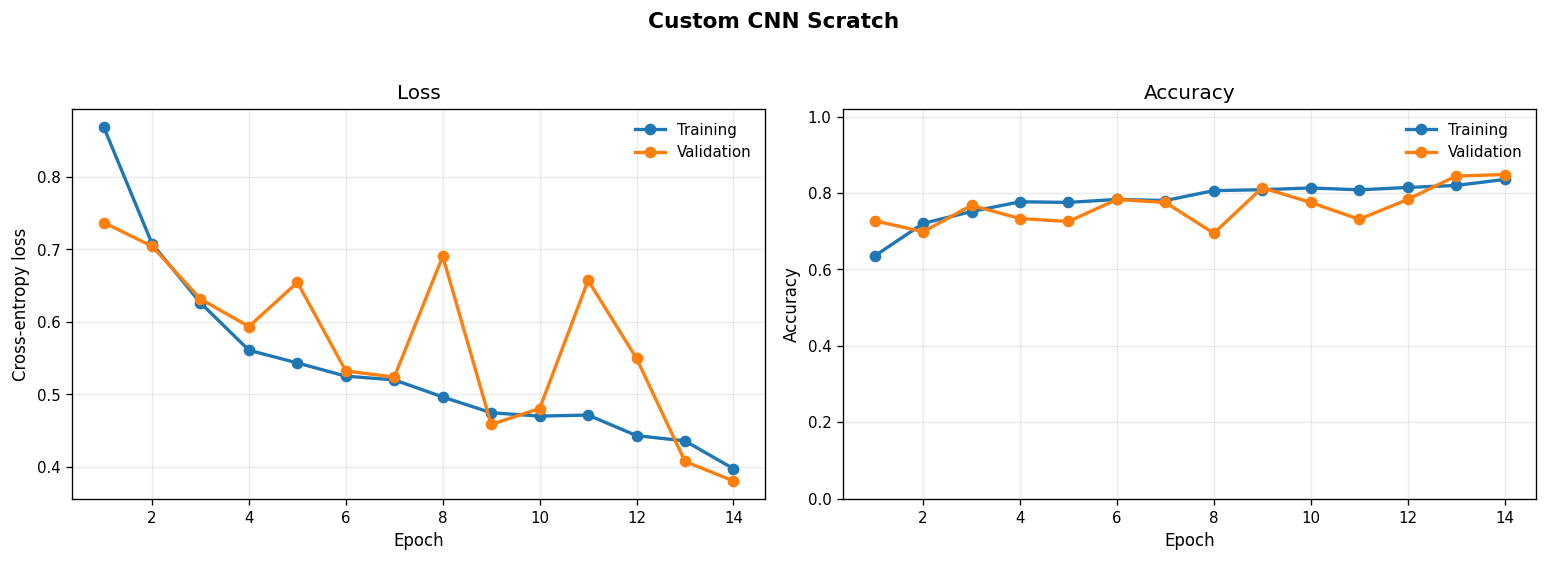

Experiment: Custom CNN Scratch + Dropout
Loading checkpoint instead of retraining: Custom_CNN_Scratch_lr3e-4.pt


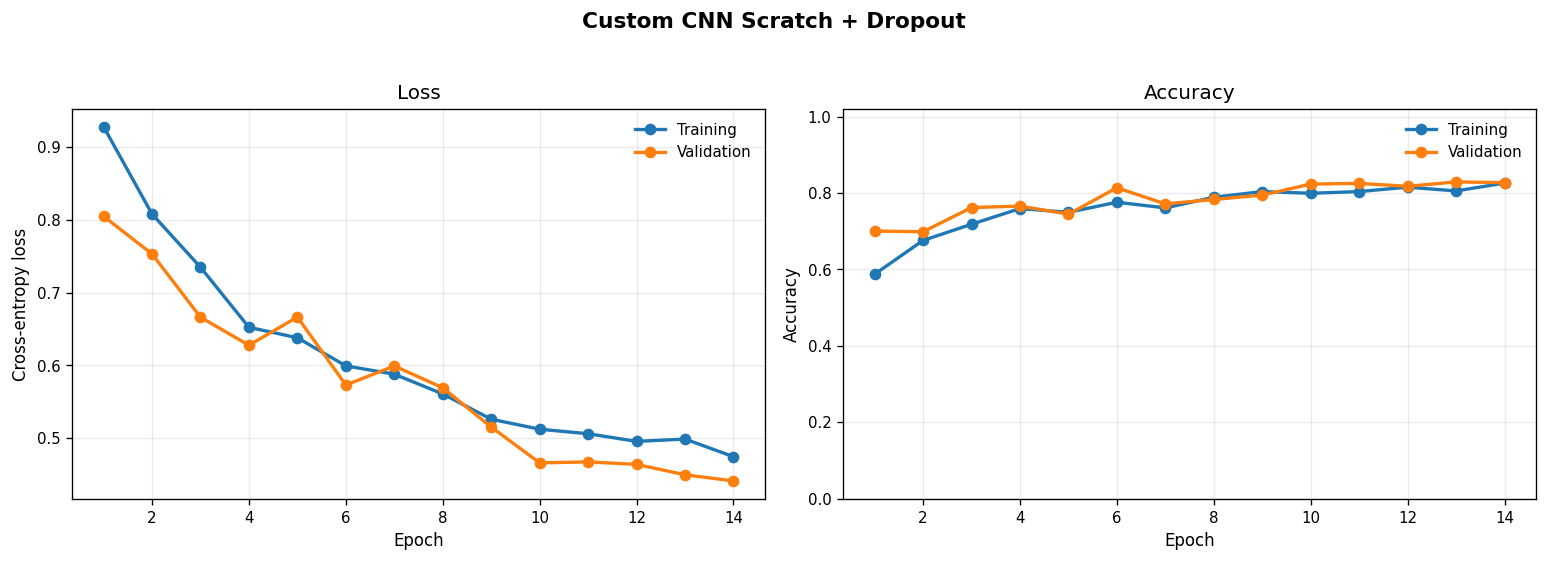

Experiment: ResNet-18 Scratch
Loading checkpoint instead of retraining: ResNet18_Scratch_lr1e-3.pt


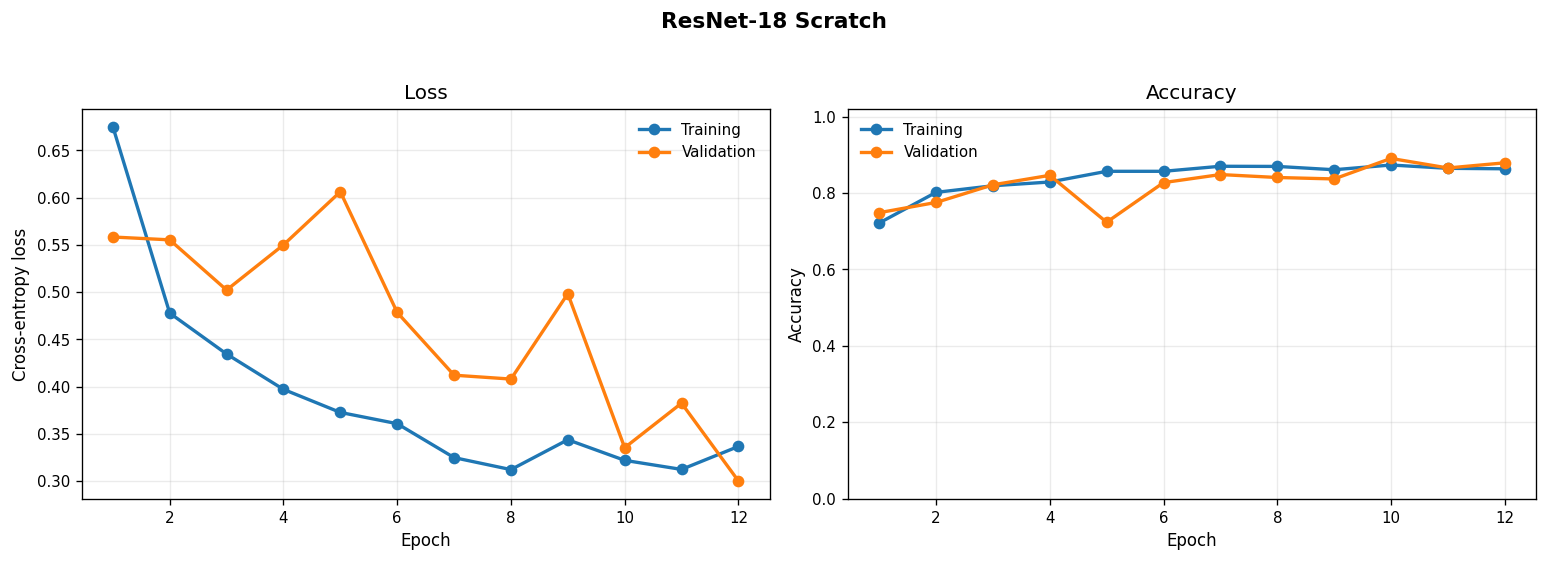

Experiment: ResNet-18 Feature Extractor
Loading checkpoint instead of retraining: ResNet18_Feature_Extractor_lr1e-3.pt


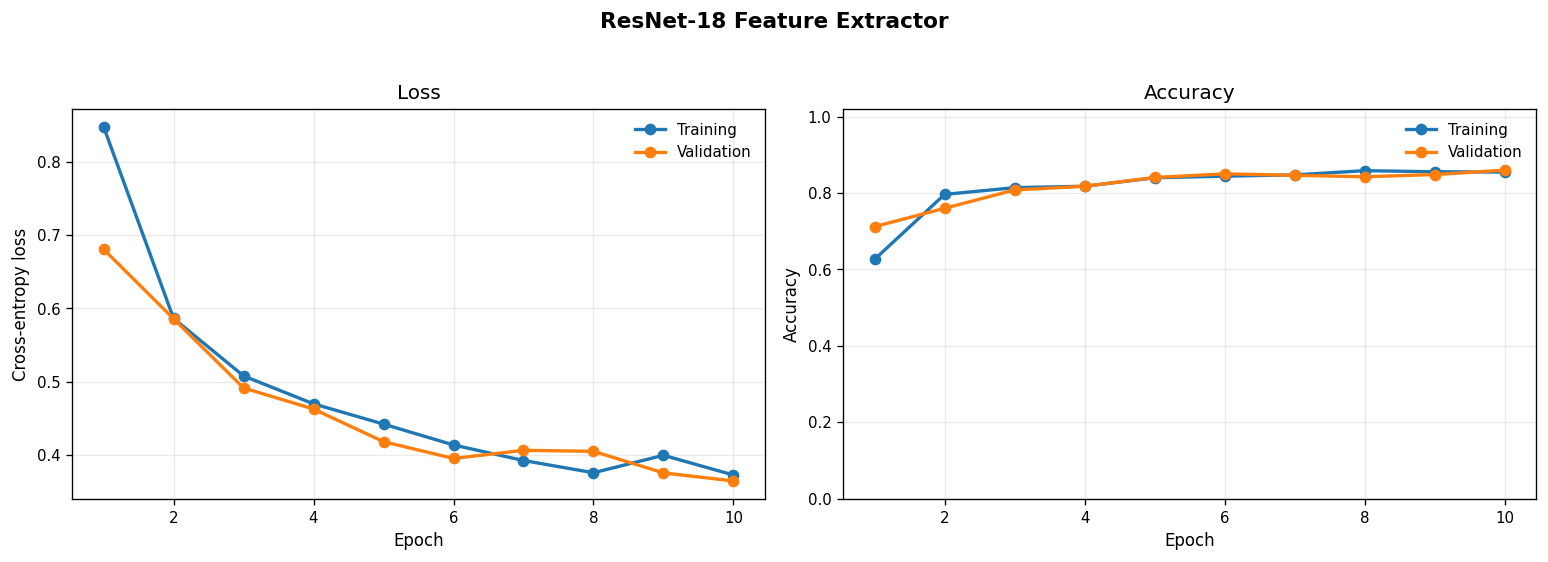

Experiment: ResNet-18 Fine-Tune
Loading checkpoint instead of retraining: ResNet18_Fine-Tuning_lr1e-4.pt


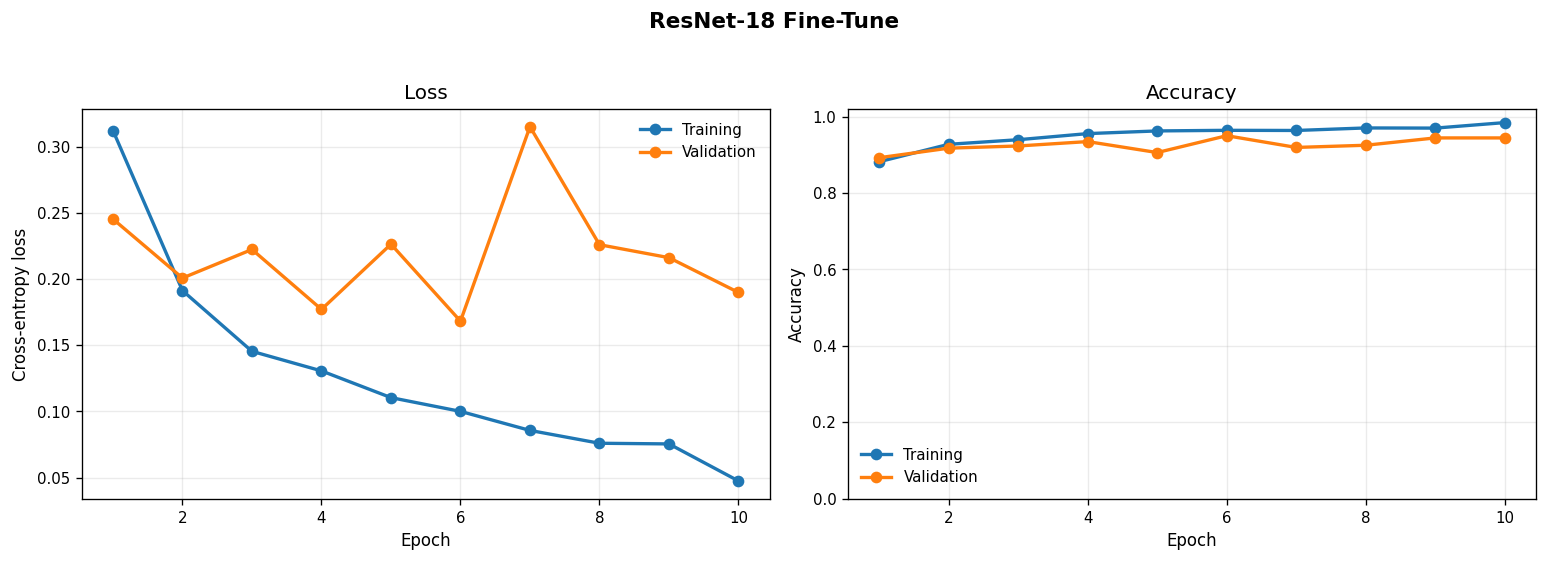

Experiment: ResNet-18 Fine-Tune (Lower LR)
Loading checkpoint instead of retraining: ResNet18_Fine-Tuning_lr3e-5.pt


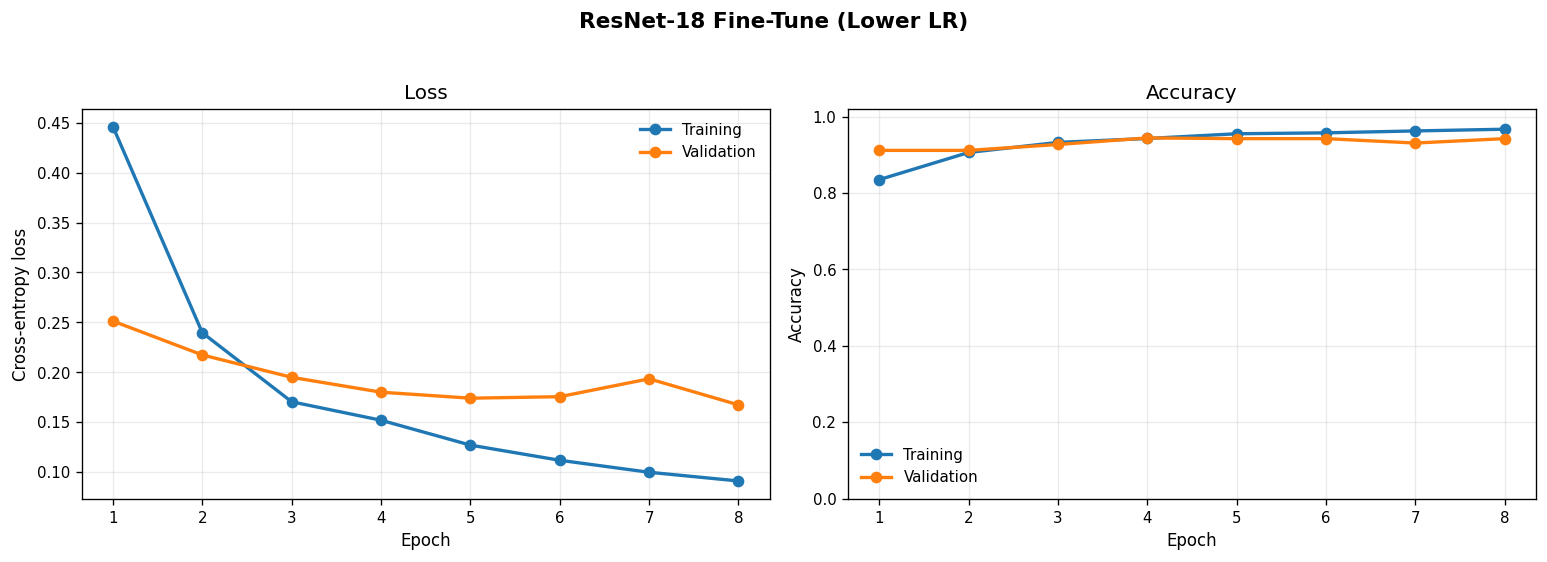

Experiment: ResNet-18 Fine-Tune + Dropout
Loading checkpoint instead of retraining: ResNet18_Fine-Tuning_Dropout_lr1e-4.pt


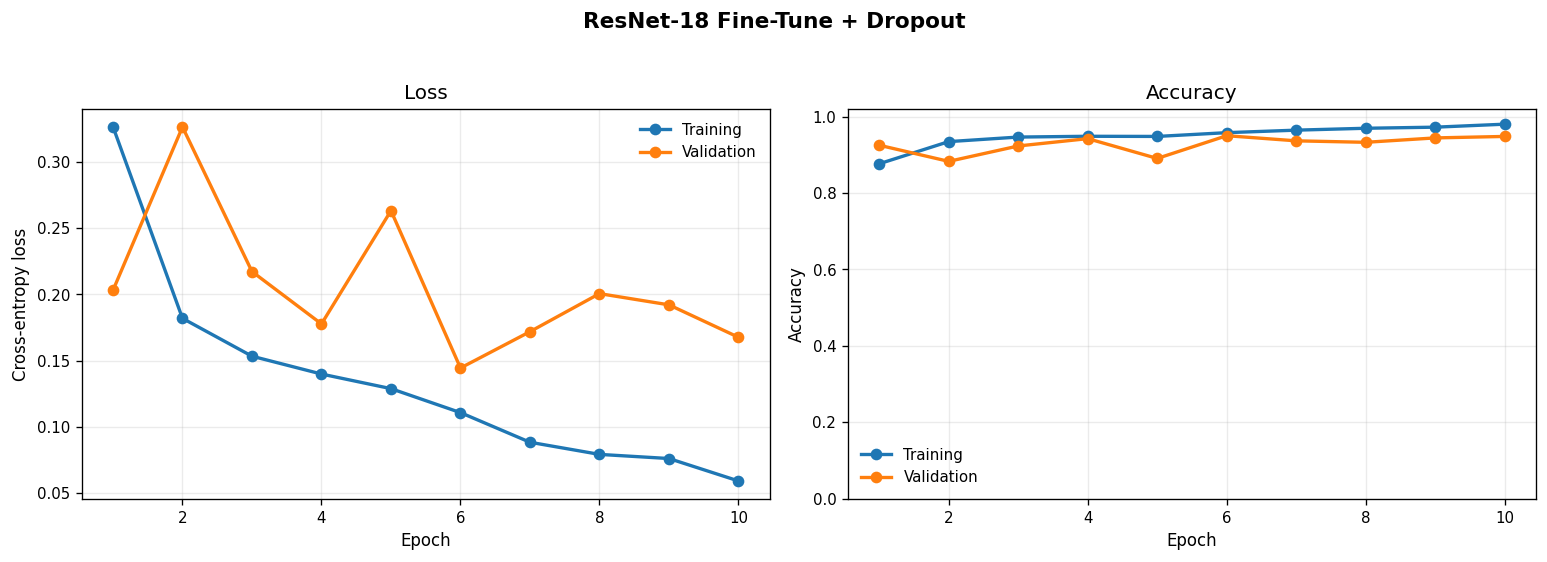

Experiment: RegNet-Y-400MF Fine-Tune
Loading checkpoint instead of retraining: RegNet-Y-400MF_Fine-Tuning_lr1e-4.pt


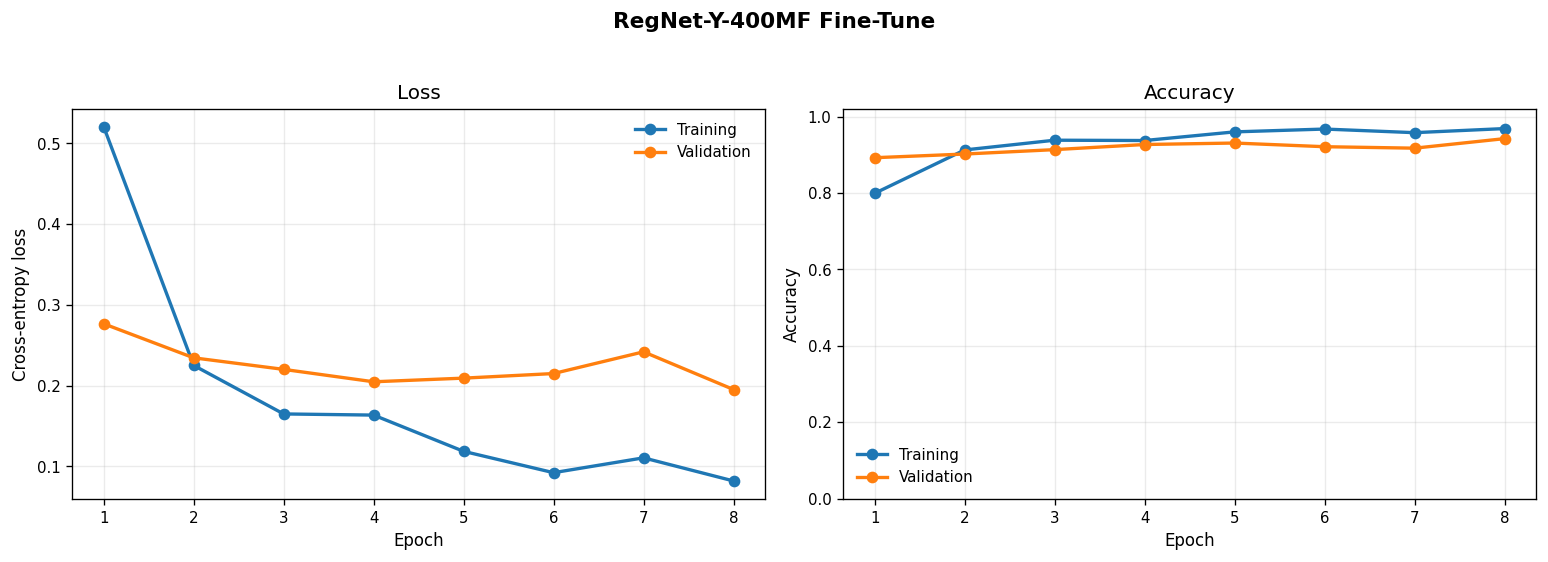

In [8]:
run_experiment_group(experiment_configs, group_name="Selected CNN experiments")


## 3.3 Validation Summary

Best validation model using macro F1: ResNet-18 Fine-Tune + Dropout


### Validation Results by Training Procedure

Models are ranked by validation macro F1, with balanced accuracy and MCC used as complementary checks.

,Model,Family,Strategy,LR,Epochs ran,Best epoch,Trainable params,Val loss,Val accuracy,Val balanced accuracy,Val macro F1,Val MCC
0,ResNet-18 Fine-Tune + Dropout,ResNet-18,Fine-tuning with dropout classifier,1e-04,10,6,11.18M,0.1444,0.9501,0.9515,0.9512,0.9252
1,ResNet-18 Fine-Tune,ResNet-18,Fine-tuning,1e-04,10,6,11.18M,0.1682,0.9501,0.9506,0.9510,0.9252
2,ResNet-18 Fine-Tune (Lower LR),ResNet-18,Fine-tuning lower learning rate,3e-05,8,4,11.18M,0.1801,0.9443,0.9452,0.9455,0.9164
3,RegNet-Y-400MF Fine-Tune,RegNet-Y-400MF,Fine-tuning second existing architecture,1e-04,8,8,3.90M,0.1952,0.9424,0.9425,0.9438,0.9138
4,ResNet-18 Scratch,ResNet-18,Scratch existing architecture,1e-03,12,10,11.18M,0.3355,0.8906,0.8908,0.8925,0.8359
5,ResNet-18 Feature Extractor,ResNet-18,Feature extractor,1e-03,10,10,1.5K,0.3647,0.8599,0.8609,0.8630,0.7898
6,Custom CNN Scratch,Custom CNN,Scratch,1e-03,14,14,79.5K,0.3809,0.8484,0.8500,0.8507,0.7723
7,Custom CNN Scratch + Dropout,Custom CNN,Scratch with stronger dropout,3e-04,14,13,79.5K,0.4498,0.8292,0.8329,0.8321,0.7439


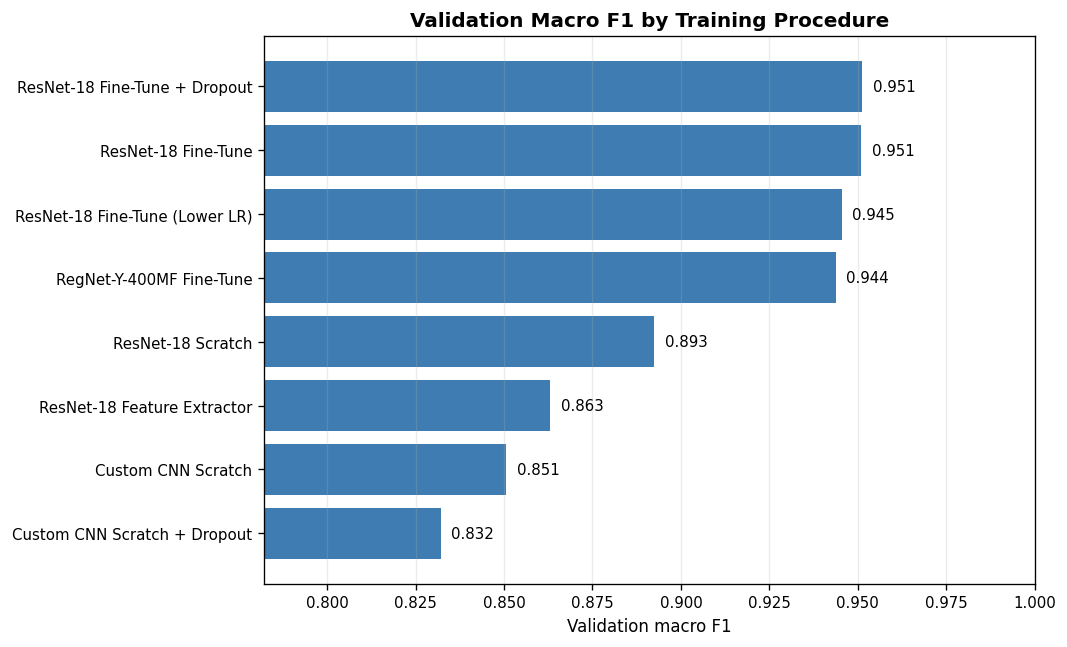

In [9]:
validation_results_df = show_validation_summary()


# 4. Evaluate Models

Only the best validation-selected model is evaluated on the held-out test set. This avoids using the test set for model selection and keeps the final result honest. The final metrics are intentionally diverse: accuracy, balanced accuracy, macro F1, and MCC, plus per-class results and a confusion matrix.

Evaluating the best validation model on the held-out test set: ResNet-18 Fine-Tune + Dropout
Majority-class baseline accuracy on the test split: 0.3602


### Held-Out Test Performance

The model was selected only from validation results; this table is the final held-out test evaluation.

,Selected model,Loss,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1,MCC,Majority baseline
0,ResNet-18 Fine-Tune + Dropout,0.1855,0.9368,0.9376,0.9389,0.9376,0.9381,0.9051,0.3602


### Per-Class Test Performance

Per-class metrics highlight which lung-condition categories are easiest or hardest to identify.

,Precision,Recall,F1 score,Support
Normal,0.9016,0.9255,0.9134,188.0
Opacity,0.9212,0.8994,0.9102,169.0
Pneumonia,0.9939,0.9879,0.9909,165.0
Macro average,0.9389,0.9376,0.9381,522.0
Weighted average,0.9371,0.9368,0.9368,522.0


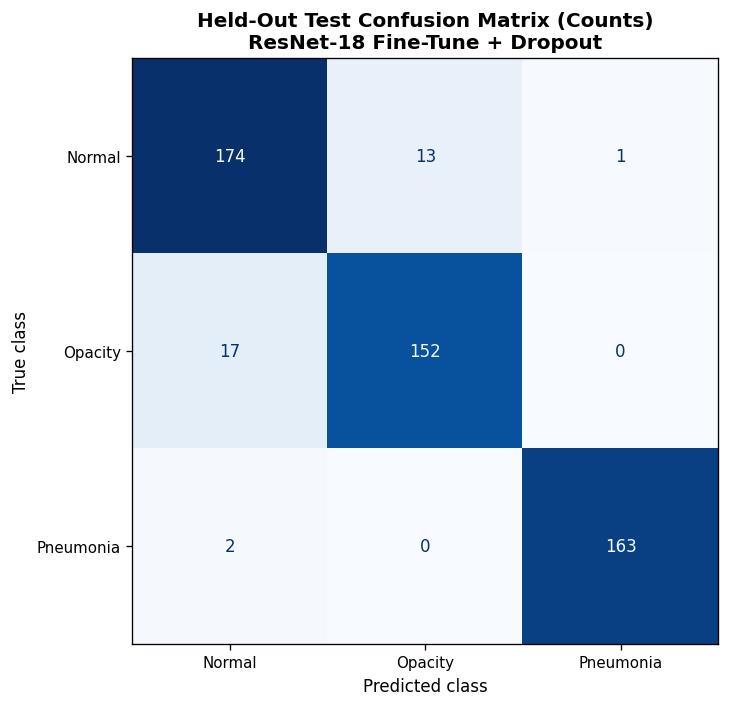

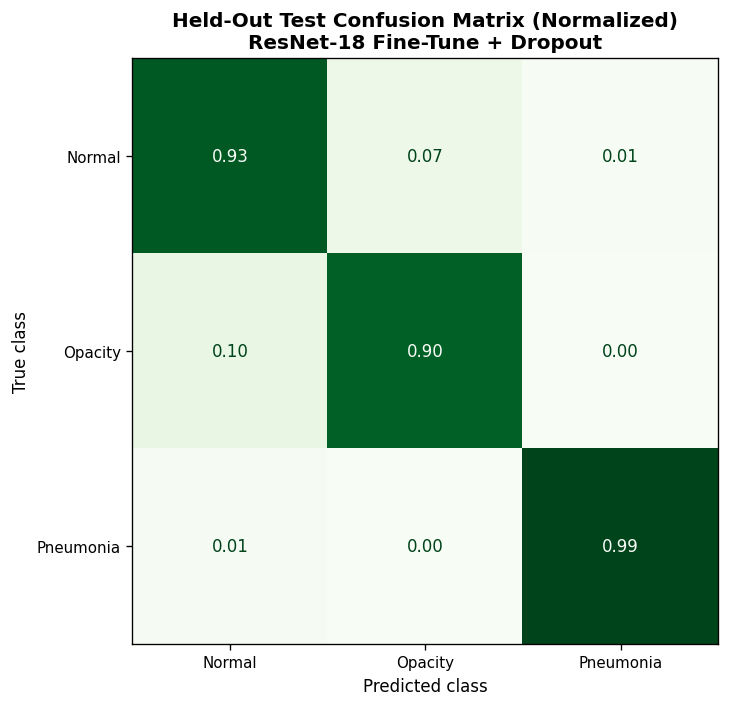

In [10]:
if "best_model_name" not in globals():
    raise RuntimeError("Run the training and validation comparison cell before final test evaluation.")

best_model_label = format_model_name(best_model_name)

# Move only the validation-selected model back to the training device for final testing.
best_model = trained_models[best_model_name].to(device)
# The test set is evaluated once, after all model selection is complete.
test_metrics, test_labels, test_preds = evaluate_model(
    best_model,
    test_loader,
    criterion,
    device,
    return_predictions=True,
)

# Majority baseline gives context: the model should beat always predicting the largest class.
majority_baseline = np.bincount(labels[test_idx], minlength=num_classes).max() / len(test_idx)

print(f"Evaluating the best validation model on the held-out test set: {best_model_label}")
print(f"Majority-class baseline accuracy on the test split: {majority_baseline:.4f}")

# Final table uses complementary metrics to address the previous feedback about repetitive metrics.
test_results_df = pd.DataFrame([
    {
        "Selected model": best_model_label,
        "Loss": test_metrics["loss"],
        "Accuracy": test_metrics["accuracy"],
        "Balanced accuracy": test_metrics["balanced_accuracy"],
        "Macro precision": test_metrics["macro_precision"],
        "Macro recall": test_metrics["macro_recall"],
        "Macro F1": test_metrics["macro_f1"],
        "MCC": test_metrics["mcc"],
        "Majority baseline": majority_baseline,
    }
])

display_table(
    "Held-Out Test Performance",
    test_results_df.round(4),
    note="The model was selected only from validation results; this table is the final held-out test evaluation.",
)

# Per-class report shows whether any lung condition is being ignored or confused.
report_dict = classification_report(
    test_labels,
    test_preds,
    target_names=class_names,
    zero_division=0,
    output_dict=True,
)
classification_report_df = pd.DataFrame(report_dict).transpose()
classification_report_df = classification_report_df.rename(
    index={"macro avg": "Macro average", "weighted avg": "Weighted average"},
    columns={"precision": "Precision", "recall": "Recall", "f1-score": "F1 score", "support": "Support"},
)
classification_report_df = classification_report_df.loc[
    class_names + ["Macro average", "Weighted average"],
    ["Precision", "Recall", "F1 score", "Support"],
]

display_table(
    "Per-Class Test Performance",
    classification_report_df.round(4),
    note="Per-class metrics highlight which lung-condition categories are easiest or hardest to identify.",
)

# Raw confusion matrix shows the count of each mistake type.
cm = confusion_matrix(test_labels, test_preds)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
    cmap=plt.cm.Blues,
    ax=ax,
    values_format="d",
    colorbar=False,
)
ax.set_title(f"Held-Out Test Confusion Matrix (Counts)\n{best_model_label}", fontweight="bold")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.tight_layout()
plt.show()

# Normalized confusion matrix makes class-wise error rates easier to compare.
cm_normalized = confusion_matrix(test_labels, test_preds, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=class_names).plot(
    cmap=plt.cm.Greens,
    ax=ax,
    values_format=".2f",
    colorbar=False,
)
ax.set_title(f"Held-Out Test Confusion Matrix (Normalized)\n{best_model_label}", fontweight="bold")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.tight_layout()
plt.show()

# Release accelerator memory after final evaluation.
best_model = best_model.to("cpu")
if device.type == "mps":
    torch.mps.empty_cache()
elif device.type == "cuda":
    torch.cuda.empty_cache()
